# OpenMP k-means

**Naam:** THOMAS TIMMERMANS & MILAN MURONI

**Studentennummer:** _2365790_ & _2262576_



## 0. Gekozen setup

| Parameter | Waarde |
|---|---|
| Dataset | *100000x5.csv* |
| Aantal punten *n* | *100000* |
| Aantal dimensies *d* | *5* |
| *k* (< 100) | *10* |
| repetitions (< 200) | *200* |
| seed | *2262576* |
| Aantal herhaalde metingen per configuratie | *5* |
| Thread-aantallen | *1 2 4 8 16 32 64 128 144 192* |
| vsc node | *mindwell batch_graniterapids* |
| Compiler + flags | *gcc 14.3.0 + -O3 -DNDEBUG -std=c++14 -fopenmp* |

## 1. Werkwijze


In [1]:
#pragma omp parallel for schedule(dynamic)
#	for (int r = 0 ; r < repetitions ; r++)
#	{
#		.......
#    }

we paralliliseren de buitense lus (repetitions)
elke repetiotion is volledig appart/onafhankelijk van elkaar
elke repetition kan wel een verschillend aantal stappen hebben waardoor de tijd varieert
daarom hebben we gekozen voor schedule(dynamic) dat zorgt ervoor dat er het moment dat een thread klaar is dat die meteen verder kan (er wordt niet op voorhand alles verdeeld)

_________________________________________________________________________________________________

In [2]:
#pragma omp critical
#    {
#        rng.pickRandomIndices(numRows, indices);
#    }

zo kan elke thread zonder een conflict met anderen threads het object rng gebruiken, anders treedt er datarace op en proberen threads tegelijk het object te gebruiken voor het genereren van de random indices.

_________________________________________________________________________________________________

In [3]:
#pragma omp critical
#		{
#			// Keep track of best clustering
#		if (distanceSquaredSum < bestDistSquaredSum) {
#				bestDistSquaredSum = distanceSquaredSum;
#				bestClusters = clusters;
#			}
#		}

deze maken we ook critical tegen dataraces bij het vergelijken of hij nu beter is, iedereen moet dit nu op een ander tijdstip doen waardoor het weer werkt


_________________________________________________________________________________________________

In [4]:
#for (int p = 0; p < numRows; p++) {	//elk punt uit dataset afgaan
#					std::pair<int, double> newCluster_distance = find_closest_centroid_index_and_distance(p, allData, numCols, centroids);
#					distanceSquaredSum += newCluster_distance.second;
#
#					if (newCluster_distance.first != clusters[p]) {	// als het punt bij een andere centroid hoort dan voorheen
#						clusters[p] = newCluster_distance.first;	// update cluster index
#						changed = true;	// er is een verandering, dus we moeten nog een stap doen
#					}
#			};

Initieel hebben we deze geparalleliseerd, dat gaf minder goede resultaten, het grootste werk ( de aparte repertitions) ging dan nog serieel

Moesten we dit er nu nog bij doen, kregen we naarmate we meer threads lieten werken een langere uitvoer tijd
Dit paralleliseren gaf dus een hoge overheaden deed dus meer slecht dan goed, hoe meer threads we gebruikten hoe slechter dit schaalde.

_________________________________________________________________________________________________

Repetitions = 20
We delen dan in feite 20 onafhankelijke taken uit aan threads in de buitenste loop!
Bij 2, 4, 8, 16 threads verdeelt OpenMP de 20 herhalingen efficient!
Daarna bij 32 of 64 threads zijn er meer threads dan dat er herhalingen zijn waardoor verschillende threads onbenut blijven wat verklaart waarom de uitvoertijd niet versnelt bij 32 en 64 t.o.v. 16 in onze output.

k = 10
met 100 000 punten en 5 dimensies is een enkele stap binnen een repetition best zwaar en moeten er veel berekeningen gebeuren. Deze hebben we echter niet geparalleliseerd omdat als we dit nog eens zouden paralleliseren ga je per repetition uitgevoerd door een aparte thread nog eens sub-threads genereren die daarna allemaal nog eens gejoint moeten worden en dit creeert een enorme overhead en maak het programma trager dan dat we niet paralleliseren!
De parallelisatie van de binenste lus, wat we zien als fine-grained parallelisatie doet dus de winst die we halen uit paralleliseren van de buitenste loop, wat we zien als coarse-grained, dus teniet.

## Aangepast: rng buiten de reps al genereren en bij het kijken of de rep beter is ook vergelijken (als de afstand hetzelde is) of de rep een lager nummer heeft (voorang) 

## 2. Vergelijking seriele tijd

Beide metingen uitgevoerd met dezelfde parameters
seed = 2262576, 
k = 10, 
repetitions = 200, 
dataset=100000x5.csv

#### Metingen seriele versie (gem + standaardafwijking) 5 metingen opgenomen

50.069 +/- 0.101 s

#### Metingen OpenMP 1-thread (gem + standaardafwijking) 5 metingen

47.693 +/- 0.052 s



#### Conclusie

De OpenMP versie met 1 thread is sneller dan de seriele versie.

Dat is niet wat we verwachten, we dachten dat de versie met 1 thread iets trager zou zijn omwille van thread beheer(tijd aanmaken,...)


### 3. Efficientie en speedup

## Gemiddelden, speedup en efficiëntie

Formules: gemiddelde tijd T̄, standaardafwijking σ ,
speedup S = T̄₁ / T̄ₚ en efficiëntie E = S / p, met T̄₁ = 47.693 s

| Threads (p) | T̄ (s) | σ (s) | Speedup S | Efficiëntie E |
|---:|---:|---:|---:|---:|
| 1   | 47.693 | 0.052 | 1.00  | 100.0% |
| 2   | 24.002 | 0.011 | 1.99  | 99.4%  |
| 4   | 12.286 | 0.065 | 3.88  | 97.0%  |
| 8   | 6.358  | 0.013 | 7.50  | 93.8%  |
| 16  | 3.376  | 0.006 | 14.13 | 88.3%  |
| 32  | 2.019  | 0.017 | 23.63 | 73.8%  |
| 64  | 1.537  | 0.010 | 31.02 | 48.5%  |
| 128 | 1.543  | 0.012 | 30.91 | 24.1%  |
| 144 | 1.546  | 0.010 | 30.84 | 21.4%  |
| 192 | 1.551  | 0.012 | 30.74 | 16.0%  |

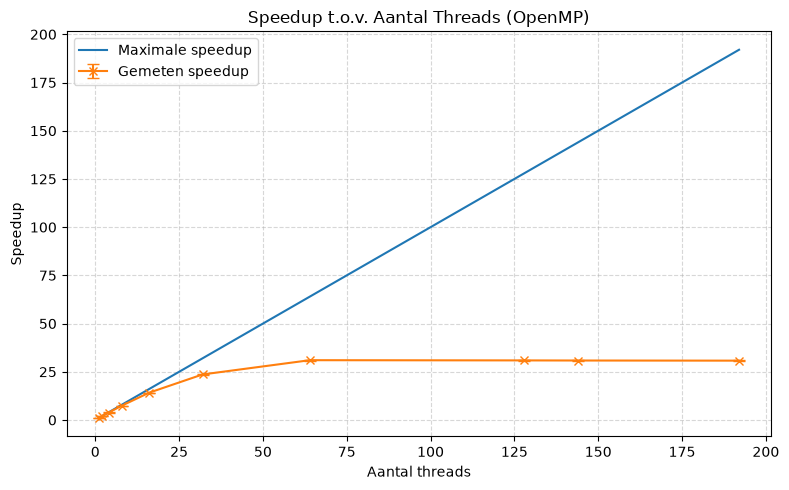

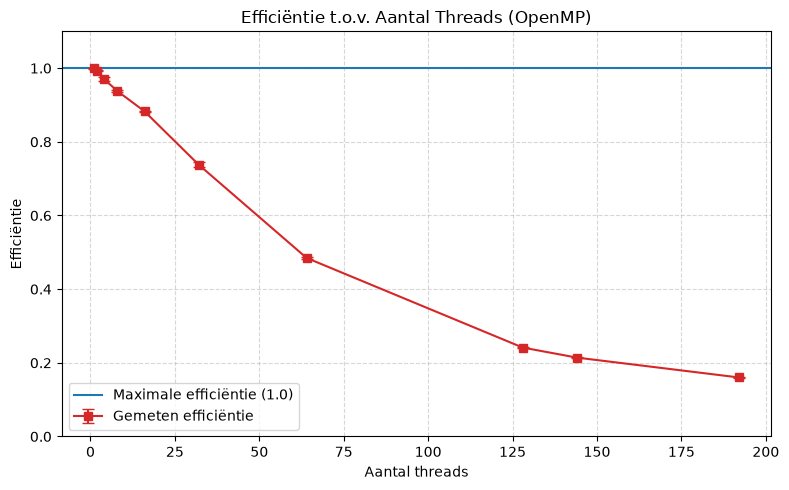

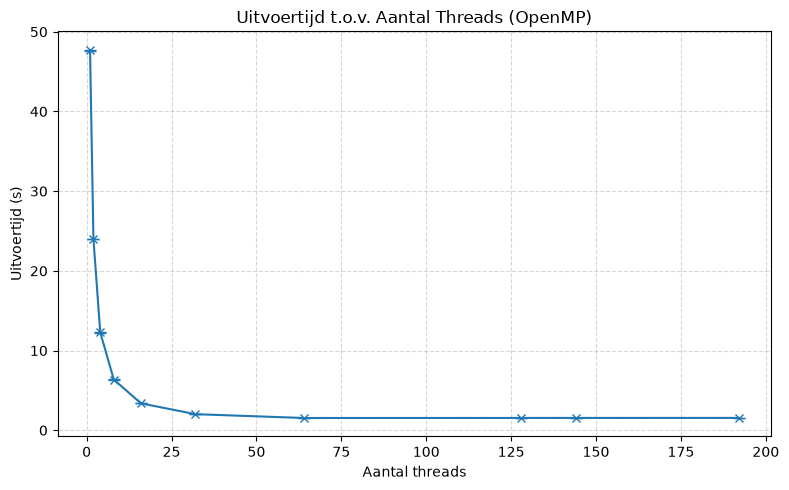

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Data uit Slurm output
threads = np.array([1, 2, 4, 8, 16, 32, 64, 128, 144, 192])
mean_times = np.array([47.6925, 24.0017, 12.2858, 6.3584, 3.3766, 2.0187, 1.5374, 1.5432, 1.5459, 1.5495])
std_times = np.array([0.0517, 0.0106, 0.0645, 0.0134, 0.0062, 0.0171, 0.0100, 0.0124, 0.0102, 0.0122])

# Referentietijd (1 thread OpenMP)
T1 = mean_times[0]
std_Ts = std_times[0]

# Berekening van Speedup en Efficiëntie (schaal 0.0 tot 1.0)
speedup = T1 / mean_times
efficiency = speedup / threads

# Foutenvoortplanting direct op Efficiëntie
std_efficiency = efficiency * np.sqrt((std_Ts / T1)**2 + (std_times / mean_times)**2)

# Foutenvoortplanting op Speedup
std_speedup = speedup * np.sqrt((std_Ts / T1)**2 + (std_times / mean_times)**2)

# Figuur 1: Speedup 
plt.figure(figsize=(8, 5))
plt.plot(threads, threads, color='tab:blue', label='Maximale speedup')
plt.errorbar(threads, speedup, yerr=std_speedup, fmt='x-', color='tab:orange', 
             capsize=4, label='Gemeten speedup')

plt.xlabel('Aantal threads')
plt.ylabel('Speedup')
plt.title('Speedup t.o.v. Aantal Threads (OpenMP)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Figuur 2: Efficiëntie 
plt.figure(figsize=(8, 5))
plt.axhline(y=1.0, color='tab:blue', linestyle='-', label='Maximale efficiëntie (1.0)')
plt.errorbar(threads, efficiency, yerr=std_efficiency, fmt='s-', color='tab:red', 
             capsize=4, label='Gemeten efficiëntie')

plt.xlabel('Aantal threads')
plt.ylabel('Efficiëntie')
plt.title('Efficiëntie t.o.v. Aantal Threads (OpenMP)')
plt.ylim(0.0, 1.1)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Figuur 3: Uitvoertijd in functie van het aantal threads (zoals voorbeeld)
plt.figure(figsize=(8, 5))
plt.errorbar(threads, mean_times, yerr=std_times, fmt='x-', color='tab:blue', 
             capsize=4, label='Gemeten uitvoertijd')

plt.xlabel('Aantal threads')
plt.ylabel('Uitvoertijd (s)')
plt.title('Uitvoertijd t.o.v. Aantal Threads (OpenMP)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Besluit

* **Speedup & Efficiëntie:** Tot 16 threads schaalt het algoritme goed: de speedup is bijna lineair ($14{,}1\times$ bij 16 threads) en de efficiëntie blijft boven $88\%$. Daarna neemt de efficiëntie af en bij 64 threads bereikt de speedup zijn maximum van ongeveer $31\times$ (efficiëntie $48{,}5\%$). Meer threads geeft daarna geen winst meer.
* **Foutbalken:** De foutbalken (standaardafwijkingen, n = 5) op alle grafieken zijn niet echt zichtbaar. Dit wilt zeggen dat de metingen zeer reproduceerbaar zijn en de uitvoertijden stabiel zijn.


##### Schaalbaarheid van de Implementatie
1. **Goede schaalbaarheid (1 - 16 threads):** De 200 herhalingen worden efficiënt verdeeld over de threads met minimale overhead. De efficiëntie blijft hoog: $99{,}4\%$ bij 2 threads, $97{,}0\%$ bij 4, $93{,}8\%$ bij 8 en $88{,}3\%$ bij 16 threads.

2. **Afnemende meeropbrengst (32 - 64 threads):** De efficiëntie daalt naar $73{,}8\%$ bij 32 en $48{,}5\%$ bij 64 threads. De speedup blijft toenemen ($23{,}6\times$ en $31{,}0\times$), maar steeds minder dan het aantal toegevoegde threads.

3. **Plateau (64 - 192 threads):** Vanaf 64 threads blijft de uitvoertijd constant rond $1{,}54$ s en de speedup rond $31\times$. De efficiëntie zakt daardoor naar $24{,}1\%$ (128 threads) en $16{,}0\%$ (192 threads). Waarschijnlijk komt dit omdat elke rep een andere hoeveelheid stappen heeft, uiteindelijk is het afhanglijkelijk van de rep met de meeste stappen, de uitvoertijd zal dan niet meer dalen, een thread moet die volledig uitvoeren. de andere threads hebben dan waarschijnlijk alle andere reps met minder stappen al uitgevoerd.. er is bv een rep met 235 stappen, die is waarschijnlijk de trage schakel.

### 4. Seriele fractie inschatten (8 threads)

T1 = 47,693s (gemiddelde tijd voor 1 thread),
T8 = 6,358s (gemiddelde tijd 8 threads)

Wet van Amdahl: Theoretische speedup Sp bij p threads:
$$S_p = \frac{1}{s + \frac{1 - s}{p}}$$

$S_8 = \frac{47{,}693}{6{,}358} \approx \mathbf{7{,}501}$ (speedup bij 8 threads),
p = 8 (8 threads)

formule omzetten naar s : $$s = \frac{\frac{1}{S_p} - \frac{1}{p}}{1 - \frac{1}{p}}$$

Waardes invullen: $$s = \frac{\frac{1}{7{,}501} - \frac{1}{8}}{1 - \frac{1}{8}} = \frac{0{,}133314 - 0{,}125}{0{,}875} = \frac{0{,}008314}{0{,}875} \approx \mathbf{0{,}0095}$$


#### Conclusie
De geschatte seriële fractie $s$ bedraagt **0,95%**. Dit betekent dat circa 99,05% van de uitvoeringstijd effectief parallel geschaald wordt. De overige 0,95% wordt veroorzaakt door het seriële deel van de code, synchronisatie-overhead (`#pragma omp critical`), beheerskosten van de OpenMP-threads en load imbalance.

### 5. Geschatte uitvoertijd (16 threads)

s = 0,0095, p = 16

$$S_{16, \text{pred}} = \frac{1}{s + \frac{1 - s}{16}} = \frac{1}{0{,}0095 + \frac{1 - 0{,}0095}{16}} = \frac{1}{0{,}0095 + 0{,}061906} = \frac{1}{0{,}071406} \approx \mathbf{14{,}004}$$

$$T_{16, \text{pred}} = \frac{T_1}{S_{16, \text{pred}}} = \frac{47{,}693}{14{,}004} \approx \mathbf{3{,}4056\text{ s}}$$

Voorspelde tijd: 3,4056 s
Gemeten tijd: 3,3766 s

==> verschil 3,3766 - 3,4056 = -0,0290 s (ongeveer 0,9%)

In werkelijkheid is het programma dus iets sneller dan Amdahl voorspelt, maar het verschil is klein. De voorspelling klopt dus goed.

## 6. Verwachtingen bij Opschalen van Cores & Limiet bij Oneindig Veel Cores

### 1. Verwachtingen bij Stijgend Aantal Cores ($p \rightarrow \infty$)
Naarmate we steeds meer CPU-cores toevoegen, zien we twee fasen:

* **Fase 1 (Afnemende meeropbrengst):** De uitvoertijd daalt aanvankelijk, maar steeds trager. Volgens de wet van Amdahl kan enkel het parallelle gedeelte ($1 - s \approx 99{,}05\%$) versneld worden. In onze metingen blijft de efficiëntie tot 16 threads boven $88\%$ en daalt ze daarna ($73{,}8\%$ bij 32 en $48{,}5\%$ bij 64 threads).
* **Fase 2 (Plateau / Verzadiging):** Vanaf 64 threads blijft de uitvoertijd constant rond $1{,}54$ s. Extra threads leveren geen winst meer op, omdat de repetitie met de meeste stappen ($235$ stappen) volledig door één thread uitgevoerd moet worden. De tijd stijgt niet merkbaar (hij blijft binnen ongeveer $0{,}012$ s tussen 64 en 192 threads).

### 2. Limiet bij oneindig veel cores

Volgens Amdahl is de maximale speedup bij een oneindig aantal cores begrensd door de seriële fractie:
$$S_{\infty} = \lim_{p \to \infty} \frac{1}{s + \frac{1 - s}{p}} = \frac{1}{s}$$

Met onze geschatte seriële fractie $s = 0{,}0095$:

$$S_{\infty} = \frac{1}{0{,}0095} \approx \mathbf{105{,}3}$$

De theoretisch minimale uitvoertijd ($T_{\infty}$) wordt dan:

$$T_{\infty} = \frac{T_1}{S_{\infty}} = s \cdot T_1 = 0{,}0095 \times 47{,}693\text{ s} \approx \mathbf{0{,}453\text{ seconden}}$$

### 3. Praktische limiet van de huidige implementatie
In onze specifieke implementatie is de maximale parallellisatie begrensd door het aantal repetities ($\text{repetitions} = 200$) en vooral door hun ongelijke lengte. Een repetitie kan hoogstens op 1 thread draaien, dus de tijd kan nooit korter zijn dan die van de langste repetitie.

De langste repetitie heeft $235$ stappen, van in totaal $8023$ stappen. De maximale speedup is daardoor begrensd tot ongeveer $8023 / 235 \approx \mathbf{34}$, en de minimale uitvoertijd tot ongeveer $T_1 / 34 \approx 1{,}4$ s. Gemeten krijgen we een plateau van $1{,}54$ s ($\approx 31\times$), dicht bij die grens. Deze praktische limiet ligt dus veel lager dan de Amdahl-limiet van $105{,}3\times$ ($0{,}453$ s).

## 7. Op welke manieren schaalbaarheid verbeteren (oude versie)

Om de schaalbaarheid voorbij 16 en 20 threads te verbeteren, moeten we de seriële fractie $s$ verkleinen en fijnerkorrelige (*fine-grained*) parallelisatie toepassen.

### 1. Verwijderen/Optimaliseren van Kritieke Secties (`#pragma omp critical`)
* **Idee:** Momenteel worden het genereren van random indices en het opslaan van het beste resultaat beveiligd met een `#pragma omp critical`. Dit dwingt alle threads om op elkaar te wachten (seriële bottleneck).
* **Werking:** 
  * Gebruik een thread-safe Random Number Generator in plaats van één gedeeld `rng`-object.
  * Laat elke thread zijn eigen `bestClusters` lokaal bijhouden en voer pas helemaal aan het einde van de parallelle regio één reductie of snelle vergelijking uit.
* **Vereiste werkhoeveelheid:** **Laag (1 uurtje werk).** Dit vermindert de seriële fractie $s$ direct aanzienlijk.

---

### 2. Parallelisatie binnen de K-means Iteratieloop met Reductie (Fine-grained benadering)
* **Idee:** Als de parameters zo gekozen worden dat `repetitions` klein is maar $n$ (aantal datapunten) groot, paralleliseer dan uitsluitend de iteraties binnen k-means over de $n$ datapunten.
* **Werking:** Verdeel de 100.000 punten over de beschikbare threads om afstanden te berekenen.
* **Vereiste werkhoeveelheid:** **Middelmatig werk (2 uurtjes)** 